<a href="https://colab.research.google.com/github/uday23e/CONJUGATE_DIRECTION_METHOD/blob/main/lwfsn_dip_denoising_trial_snail.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Code for **"Blind restoration of a JPEG-compressed image"** and **"Blind image denoising"** figures. Select `fname` below to switch between the two.

- To see overfitting set `num_iter` to a large value.

In [1]:
"""
*Uncomment if running on colab*
Set Runtime -> Change runtime type -> Under Hardware Accelerator select GPU in Google Colab
"""
!git clone https://github.com/DmitryUlyanov/deep-image-prior
!mv deep-image-prior/* ./

Cloning into 'deep-image-prior'...
remote: Enumerating objects: 289, done.
remote: Total 289 (delta 0), reused 0 (delta 0), pack-reused 289 (from 1)
Receiving objects: 100% (289/289), 24.28 MiB | 11.12 MiB/s, done.
Resolving deltas: 100% (155/155), done.


In [2]:

!git clone https://git.codeocean.com/capsule-9027829.git

Cloning into 'capsule-9027829'...
remote: Enumerating objects: 30, done.
remote: Counting objects: 100% (30/30), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 30 (delta 2), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (30/30), 89.61 MiB | 7.20 MiB/s, done.
Resolving deltas: 100% (2/2), done.


# Import libs

In [3]:
from __future__ import print_function
import matplotlib.pyplot as plt
%matplotlib inline

import os
#os.environ['CUDA_VISIBLE_DEVICES'] = '3'

import numpy as np
from models import *

import torch
import torch.optim

from skimage.metrics import peak_signal_noise_ratio as compare_psnr

from utils.denoising_utils import *

torch.backends.cudnn.enabled = True
torch.backends.cudnn.benchmark =True
dtype = torch.cuda.FloatTensor

imsize =-1
PLOT = True
sigma = 25
sigma_ = sigma/255.

In [4]:
# deJPEG
fname = 'data/denoising/snail.jpg'

## denoising
#fname = 'data/denoising/F16_GT.png'

# Load image

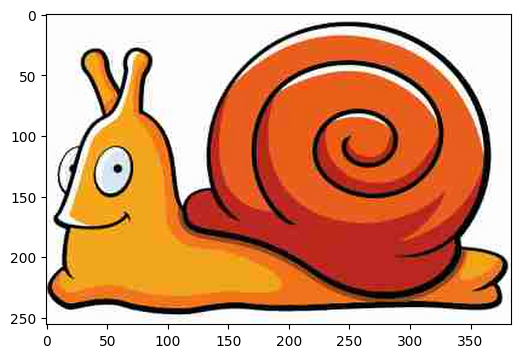

In [5]:
if fname == 'data/denoising/snail.jpg':
    img_noisy_pil = crop_image(get_image(fname, imsize)[0], d=32)
    img_noisy_np = pil_to_np(img_noisy_pil)

    # As we don't have ground truth
    img_pil = img_noisy_pil
    img_np = img_noisy_np

    if PLOT:
        plot_image_grid([img_np], 4, 5);

elif fname == 'data/denoising/F16_GT.png':
    # Add synthetic noise
    img_pil = crop_image(get_image(fname, imsize)[0], d=32)
    img_np = pil_to_np(img_pil)

    img_noisy_pil, img_noisy_np = get_noisy_image(img_np, sigma_)

    if PLOT:
        plot_image_grid([img_np, img_noisy_np], 4, 6);
else:
    assert False

# Setup

In [6]:
'''#code by author, dip
INPUT = 'noise' # 'meshgrid'
pad = 'reflection'
OPT_OVER = 'net' # 'net,input'
reg_noise_std = 1./30. # set to 1./20. for sigma=50
LR = 0.01

OPTIMIZER='adam' # 'LBFGS'
show_every = 100
exp_weight=0.99

if fname == 'data/denoising/snail.jpg':
    num_iter = 2400
    input_depth = 3
    figsize = 5

    net = skip(
                input_depth, 3,
                num_channels_down = [8, 16, 32, 64, 128],
                num_channels_up   = [8, 16, 32, 64, 128],
                num_channels_skip = [0, 0, 0, 4, 4],
                upsample_mode='bilinear',
                need_sigmoid=True, need_bias=True, pad=pad, act_fun='LeakyReLU')

    net = net.type(dtype)

elif fname == 'data/denoising/F16_GT.png':
    num_iter = 3000
    input_depth = 32
    figsize = 4


    net = get_net(input_depth, 'skip', pad,
                  skip_n33d=128,
                  skip_n33u=128,
                  skip_n11=4,
                  num_scales=5,
                  upsample_mode='bilinear').type(dtype)

else:
    assert False

net_input = get_noise(input_depth, INPUT, (img_pil.size[1], img_pil.size[0])).type(dtype).detach()

# Compute number of parameters
s  = sum([np.prod(list(p.size())) for p in net.parameters()]);
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)

img_noisy_torch = np_to_torch(img_noisy_np).type(dtype)
'''

#edited for lwfsn
import sys
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential

#from .kernels import convKernel
#from .dwtHaar import dwtHaar_2d, idwtHaar_2d
#from .customActivations import semiH_threshold4

# Add the parent 'code' directory to Python's search path so it can locate the modules
sys.path.append(os.path.abspath('/content/capsule-9027829/code'))

# Absolute imports from the cnnModels directory package
from cnnModels.kernels import convKernel
from cnnModels.dwtHaar import dwtHaar_2d, idwtHaar_2d
from cnnModels.customActivations import semiH_threshold4

""" Class: __threshold_learn__
    Description:  This class implements the LET threshold used in
            the LWFSN CNN
    constructor:
        * nts: Number of thresholds
    forward inputs:
        * D: Input detail bands generated by a (learned) framelet
    forward outputs:
        * out: thresholded signal
"""
class __threshold_learn__(nn.Module):
    def __init__(self, nts):
        super(__threshold_learn__, self).__init__()

        amp = 1e-3

        # Global thresholds
        self.t = nn.Parameter( torch.rand((nts,1,1)))
        #self.t.data.uniform_(0, 0.001)

        self.a = nn.Parameter( torch.ones((1,nts,1,1)))

        self.nts =nts

    def forward(self, D):
        ds = D.shape
        Dr = D.reshape([ds[0]*ds[1], 1, ds[2], ds[3]])

        # Thresholding
        rep =  Dr.repeat( 1, self.nts, 1, 1)
        t = semiH_threshold4(rep,  self.t)


        # Mixing
        b = self.__softmax__(self.a)
        out = F.conv2d(t, b, bias = None, stride=(1,1), padding=0)

        return(  out.reshape([ds[0], ds[1], ds[2], ds[3]]) )

    def __softmax__(self,x):
        xs = x.shape
        xp = x.reshape(-1)
        xe = torch.exp(x)
        sf = xe/torch.sum(xe)
        return( sf.reshape(xs) )



""" Class: lwfsn_2d
    Description:  This class implements the LWFSN CNN
    constructor:
        * in_channels: Number of channels of the input image
        * depth: Depth of the CNN
        * wf: Number of channels after first convolution
    forward inputs:
        * x: Input image to be processed
        * bypass_shrinkage: If True, the LET threshold is ignored
    forward outputs:
        * LL: Denoised image
"""
class lwfsn_2d(nn.Module):
    def __init__( self, in_channels=1, depth=1, wf=4):
        super(lwfsn_2d, self).__init__()
        self.depth = depth

        # Encoding path
        self.shrink = nn.ModuleList()

        self.ew1 = nn.ModuleList()
        self.ew2 = nn.ModuleList()

        self.dw1 = nn.ModuleList()
        self.dw2 = nn.ModuleList()

        nts = 5
        prev_channels = in_channels
        for i in range(depth):
            out_channels = wf*2**i
            # Thresholds
            self.shrink+= [__threshold_learn__( nts ) ]
            # Weight for the wavelet frame
            self.ew1+= [convKernel(out_channels//2, prev_channels, 2, 2) ]
            self.ew2+= [convKernel(out_channels, out_channels//2, 2, 2) ]

            self.dw1+= [convKernel(out_channels//2, prev_channels, 2, 2) ]
            self.dw2+= [convKernel(out_channels, out_channels//2, 2, 2) ]

            # Other relevant constants
            prev_channels = out_channels

        # Defining inverse and forward transforms
        self.dwt = dwtHaar_2d()
        self.idwt = idwtHaar_2d()
        self.__set_requires_grad__(self.dwt, False)
        self.__set_requires_grad__(self.idwt, False)


    def forward(self, x, bypass_shrinkage=False):
        xs = x.shape
        LH_list = []; HL_list = []; HH_list = []

        LL = x
        for i in range(self.depth):
            # Loading kernels
            # Convoluting signal with factorized wavelet frame
            LL, LH, HL, HH = self.__forwardF__(LL, i)

            lls = LL.shape
            # Processing bands, we define also a bypass option for training the
            # Encoding and decoding path
            if not bypass_shrinkage:
                # Shrinklage stage
                cat = torch.cat([LH, HL, HH], axis=1)
                LH, HL, HH = torch.split(self.shrink[i](cat), LH.shape[1], dim=1)

            LH_list.append( LH )
            HL_list.append( HL )
            HH_list.append( HH )

        # Inverse transforming
        for i in range(self.depth):
            indx = self.depth - i -1
            LH = LH_list[indx]
            HL = HL_list[indx]
            HH = HH_list[indx]

            # Inverse-wavelet transforming
            LL  = self.__inverseF__(LL, LH, HL, HH, indx)

        return(LL)

    def __set_requires_grad__(self, net, requires_grad=False):
        for param in net.parameters():
            param.requires_grad = requires_grad

    def __forwardF__(self, x, i):
        # Loading the weights
        W1 = self.ew1[i]()
        W2 = self.ew2[i]()

        # Convolutions
        xp = F.pad(x,(1,1,1,1), mode="constant")
        xW1 = F.conv2d(xp, W1, bias = None, stride=(1,1), padding=0)
        xW2 = F.conv2d(xW1, W2, bias = None, stride=(1,1), padding=0)
        return(self.dwt(xW2))

    def __inverseF__(self, LL, LH, HL, HH, i):
        # Loading the weights
        WT1 = self.dw1[i]().transpose(1,0)
        WT2 = self.dw2[i]().transpose(1,0)

        #Inverse frame transform
        iw= self.idwt(LL, LH, HL, HH)
        xp = F.pad(iw,(1,1,1,1), mode="constant")
        x2 = F.conv2d(xp, WT2, bias = None, stride=(1,1), padding=0)
        x1 = F.conv2d(x2, WT1, bias = None, stride=(1,1), padding=0)
        return(x1 )

INPUT = 'noise' # 'meshgrid'
pad = 'reflection'
OPT_OVER = 'net' # 'net,input'

reg_noise_std = 1./30. # set to 1./20. for sigma=50
LR = 0.0022

OPTIMIZER='adam' # 'LBFGS'
show_every = 100
exp_weight=0.99
'''
if fname == 'data/denoising/snail.jpg':
    num_iter = 2400
    input_depth = 3
    figsize = 5

    # input_depth is 3, so lwfsn_2d natively outputs 3 channels.
    # We just append Sigmoid to bound the RGB values.
    net = nn.Sequential(
        lwfsn_2d(in_channels=input_depth, depth=5, wf=8),
        nn.Sigmoid()
    )
    net = net.type(dtype)

elif fname == 'data/denoising/F16_GT.png':
    num_iter = 3000
    input_depth = 32
    figsize = 4

    # input_depth is 32. lwfsn_2d outputs 32 channels, so we use a 1x1
    # convolution to project it down to 3 RGB channels before Sigmoid.
    net = nn.Sequential(
        lwfsn_2d(in_channels=input_depth, depth=5, wf=8),
        nn.Conv2d(input_depth, 3, kernel_size=1, stride=1, padding=0, bias=True),
        nn.Sigmoid()
    )
    net = net.type(dtype)
'''
if fname == 'data/denoising/snail.jpg':
    num_iter = 3000
    input_depth = 3
    figsize = 5

    # input_depth is 3, so lwfsn_2d natively outputs 3 channels.
    # We use Sigmoid *only* at the final step to bound RGB independently between 0 and 1.
    net = nn.Sequential(
        lwfsn_2d(in_channels=input_depth, depth=5, wf=8),
        nn.Sigmoid()
    )
    net = net.type(dtype)

elif fname == 'data/denoising/F16_GT.png':
    num_iter = 1500
    input_depth = 32
    figsize = 4

    # input_depth is 32. We project the 32 channels down to 3 independent RGB channels
    # using a 1x1 conv, then apply Sigmoid to scale it for image viewing.
    net = nn.Sequential(
        lwfsn_2d(in_channels=input_depth, depth=5, wf=8),
        nn.Conv2d(input_depth, 3, kernel_size=1, stride=1, padding=0, bias=True),
        nn.Sigmoid()
    )
    net = net.type(dtype)


else:
    assert False

net_input = get_noise(input_depth, INPUT, (img_pil.size[1], img_pil.size[0])).type(dtype).detach() *15.0

# Compute number of parameters
s  = sum([np.prod(list(p.size())) for p in net.parameters()]);
print ('Number of params: %d' % s)

# Loss
mse = torch.nn.MSELoss().type(dtype)

img_noisy_torch = np_to_torch(img_noisy_np).type(dtype)

Number of params: 130962


# Optimize

In [7]:
# Add a tiny gradient leak (0.01 * cat) to ensure
# the backward pass always receives a gradient even if the threshold zeroes out.
#processed_cat = self.shrink[i](cat) + 0.01 * cat

#LH, HL, HH = torch.split(processed_cat, LH.shape[1], dim=1)
#To improve psnr after altering learning rate, this change is applied onto the lwfsn part in the file 'cnnModels' below the part:
# Shrinklage stage
                #cat = torch.cat([LH, HL, HH], axis=1)

Starting optimization with ADAM


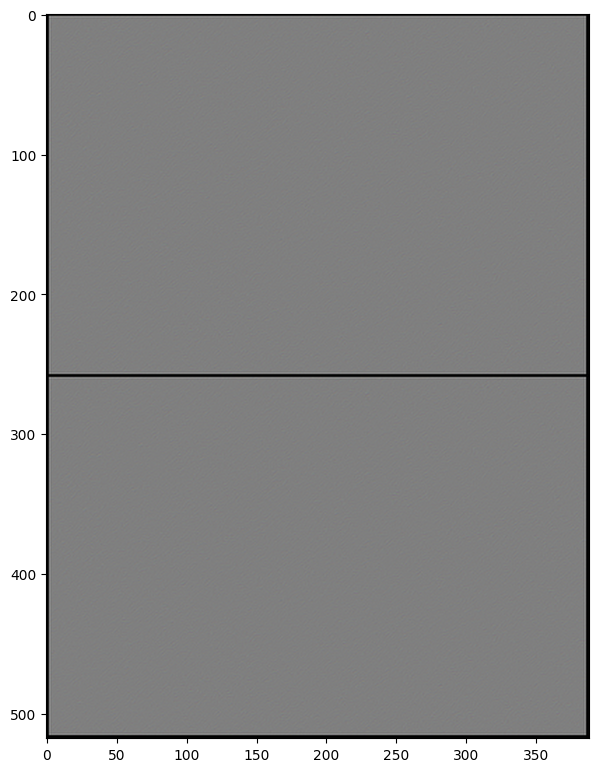

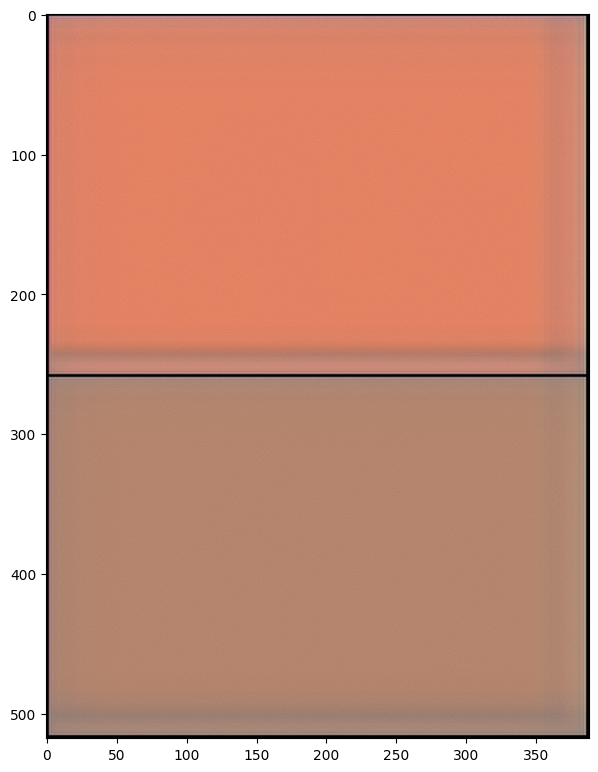

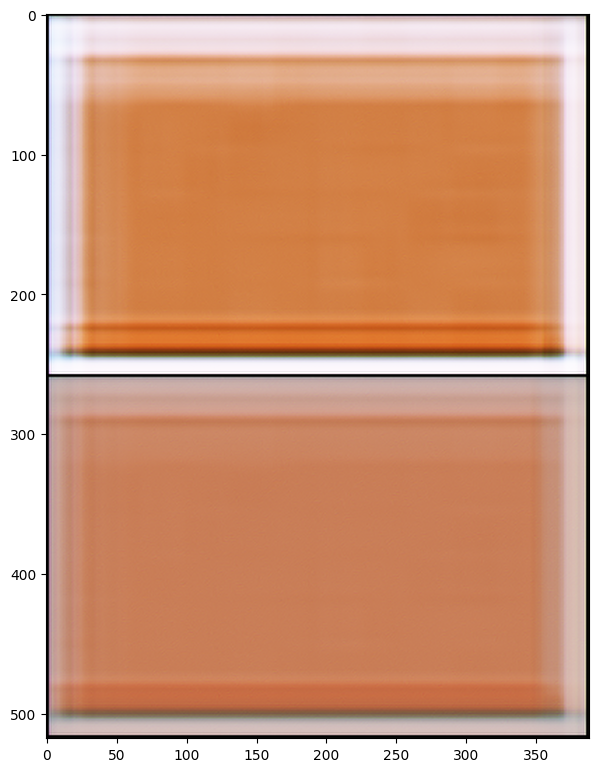

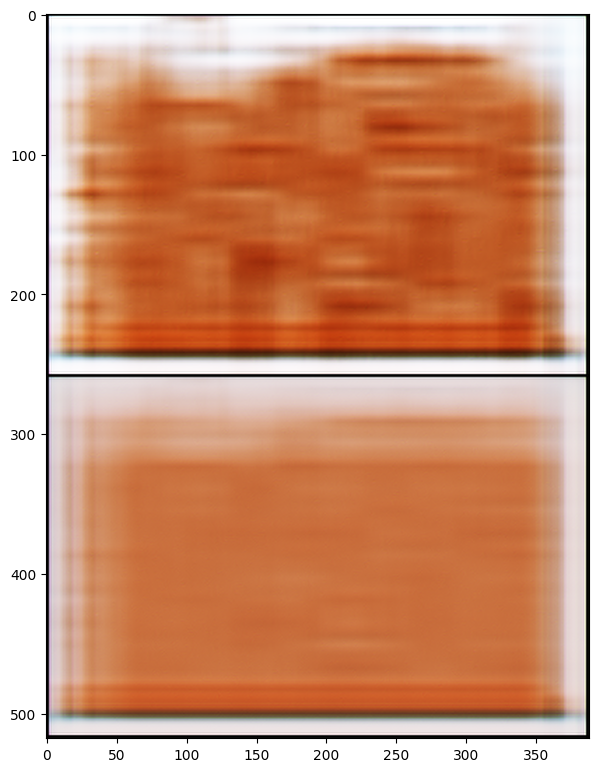

In [ ]:
net_input_saved = net_input.detach().clone()
noise = net_input.detach().clone()
out_avg = None
last_net = None
psrn_noisy_last = 0

i = 0
def closure():

    global i, out_avg, psrn_noisy_last, last_net, net_input

    if reg_noise_std > 0:
        net_input = net_input_saved + (noise.normal_() * reg_noise_std)

    out = net(net_input)

    # Smoothing
    if out_avg is None:
        out_avg = out.detach()
    else:
        out_avg = out_avg * exp_weight + out.detach() * (1 - exp_weight)

    total_loss = mse(out, img_noisy_torch)
    total_loss.backward()
    #print("Threshold gradients:", net[0].shrink[0].t.grad)
    #print("Conv weights gradients:", net[0].ew1[0]().grad)



    psrn_noisy = compare_psnr(img_noisy_np, out.detach().cpu().numpy()[0])
    psrn_gt    = compare_psnr(img_np, out.detach().cpu().numpy()[0])
    psrn_gt_sm = compare_psnr(img_np, out_avg.detach().cpu().numpy()[0])

    # Note that we do not have GT for the "snail" example
    # So 'PSRN_gt', 'PSNR_gt_sm' make no sense
    print ('Iteration %05d    Loss %f   PSNR_noisy: %f   PSRN_gt: %f PSNR_gt_sm: %f' % (i, total_loss.item(), psrn_noisy, psrn_gt, psrn_gt_sm), '\r', end='')
    if  PLOT and i % show_every == 0:
        out_np = torch_to_np(out)
        plot_image_grid([np.clip(out_np, 0, 1),
                         np.clip(torch_to_np(out_avg), 0, 1)], factor=figsize, nrow=1)



    # Backtracking
    if i % show_every:
        if psrn_noisy - psrn_noisy_last < -5:
            print('Falling back to previous checkpoint.')

            for new_param, net_param in zip(last_net, net.parameters()):
                net_param.data.copy_(new_param.cuda())

            return total_loss*0
        else:
            last_net = [x.detach().cpu() for x in net.parameters()]
            psrn_noisy_last = psrn_noisy

    i += 1

    return total_loss

p = get_params(OPT_OVER, net, net_input)
optimize(OPTIMIZER, p, closure, LR, num_iter)

In [ ]:
out_np = torch_to_np(net(net_input))
q = plot_image_grid([np.clip(out_np, 0, 1), img_np], factor=13);

In [ ]:
import numpy as np

# 1. Generate the network output and convert to numpy
out_np = torch_to_np(net(net_input))

# 2. Clip the output to match standard image bounds [0, 1]
out_clipped = np.clip(out_np, 0, 1)

# 3. Calculate Mean Squared Error (MSE) between output and input target
mse_val = np.mean((out_clipped - img_np) ** 2)

# 4. Calculate Peak Signal-to-Noise Ratio (PSNR)
if mse_val > 0:
    psnr_val = 10 * np.log10(1.0 / mse_val)
    print(f"=== Performance Evaluation ===")
    print(f"PSNR (Output vs Input Target): {psnr_val:.2f} dB")
    print(f"==============================")
else:
    print("PSNR (Output vs Input Target): inf dB (Perfect match)")

In [ ]:
'''
The best results so far for the snail.jpg is PSNR of 24.47 dB with the learning rate 0.002.
3000 iterations in 2-3 minutes.
But this model doesn't work on F-16.jpg, so we ended up with a red solid image with a PSNR
of 3.90 dB, which is very poor.
500 iterations: 14.93 dB
1000 iterations: 15.64 dB
1500 iterations: 5.59 dB
#FAIL.
'''

